# Types of Data & Data Collection Strategies

## 1. Topic Overview
This notebook provides an exhaustive, interview-grade breakdown of statistical data taxonomy and experimental data acquisition methods based on fundamental data science foundations.

### Learning Objectives:
- **Taxonomy of Data**: Deconstruct qualitative (nominal, ordinal) vs. quantitative (interval, ratio) levels of measurement.
- **Granular Distinctions**: Dissect discrete vs. continuous variables and evaluate why specific central tendency metrics (e.g., mean vs. mode) succeed or break down mathematically.
- **Python Implementation & Profiling**: Implement programmatic synthesis, distribution inspection, frequency tabulation, and descriptive summary generation using `numpy`, `pandas`, `scipy.stats`, and `matplotlib`.
- **Data Collection Architectures**: Analyze surveys, experiments, and observational studies—evaluating causal inference, confounding variables, and systematic bias.
- **Sampling Paradigms**: Unpack population vs. sample dynamics, exit polling mechanics, quality control sampling, and why simple random sampling (SRS) fails in stratified or skewed populations.



## 2. Exhaustive Concept Inventory

This module comprehensively dissects **16 core technical concepts**:

1. **Qualitative Data (Categorical Foundation)**: Non-numeric attribute modeling, discrete set boundaries.
2. **Nominal Data**: Unordered categorical representations, identity relations ($=$ vs $\neq$).
3. **Ordinal Data**: Rank-ordered categories with non-uniform inter-class intervals.
4. **Quantitative Data (Numerical Foundation)**: Measurable numeric data spaces and arithmetic operations.
5. **Interval Data**: Meaningful equal intervals with arbitrary/relative zero ($0^\circ\text{F}$, $0^\circ\text{C}$).
6. **Ratio Data**: Constant interval step with an absolute physical true zero ($0\text{ K}$, $\$0.00$).
7. **Discrete Quantitative Data**: Countable integer state spaces ($\mathbb{N}_0$) and discrete probability mass.
8. **Continuous Quantitative Data**: Uncountably infinite real state spaces ($\mathbb{R}$) and probability density.
9. **Descriptive Metrics on Discrete Data**: Meaningfulness of $\text{Mode}$ and $\text{Mean}$ on discrete counts.
10. **Descriptive Metrics on Continuous Data**: Degeneracy of sample mode in continuous floats and empirical workarounds.
11. **Data Collection: Surveys**: Self-reported cross-sectional telemetry, non-response bias, and social desirability.
12. **Data Collection: Controlled Experiments**: Randomized controlled trials (RCTs), independent variable manipulation, control groups, and causal inference.
13. **Data Collection: Observational Studies**: Passive naturalistic recording, confounding variables, and impossibility of counterfactual causality.
14. **Sampling Foundations**: Population parameters ($\mu, \sigma$) vs. Sample statistics ($\bar{x}, s$), exit polls, industrial quality control.
15. **Limitations of Simple Random Sampling (SRS)**: Sample allocation variance, underrepresented subpopulation bias, and class imbalance.
16. **Encoding & Analytical Strategy**: Categorical-to-numeric representations (`LabelEncoder`, `OneHotEncoder`, ordered categorical dtypes) for ML feature stores.



## 3. Deep-Dive Interview Technical Questions & Answers

---

### Concept 01: Qualitative (Categorical) Data Taxonomy
**Question:**
> How is qualitative data defined mathematically in feature engineering, and what are the strict limitations on mathematical operations performed on qualitative features?

**Answer:**
- **Theoretical Intuition:** Qualitative data represents categorical labels describing attributes or characteristics that inhabit a finite or countably infinite discrete domain without inherent physical measurement units.
- **Technical Mechanics:** A qualitative random variable maps sample space outcomes $\Omega$ into a discrete set of symbols $\mathcal{C} = \{c_1, c_2, \dots, c_k\}$. Basic arithmetic operations ($+, -, \times, \div$) are mathematically undefined and invalid.
- **Key Terminology:** Categorical feature, Cardinality, Support set, Polymorphism.
- **Return Behavior:** String object, boolean flag, or categorical scalar/vector.
- **Computational Profiling:** Memory footprint is typically $\mathcal{O}(N)$ references. In pandas, unoptimized `object` dtype strings take $8$ bytes per pointer plus heap object overhead (~50-80 bytes/string); casting to `'category'` converts this to integer codes (1 to 4 bytes per element) plus a tiny category lookup table.
- **Practical Relevance:** Feeding raw categorical labels directly into linear models or gradient descent optimizers triggers runtime exceptions; they must be encoded into numerical representations (e.g., one-hot or target encoding).



In [1]:
import numpy as np
import pandas as pd

# Demonstration: Memory footprint of Qualitative data as 'object' vs 'category'
raw_colors = ['Red', 'Blue', 'Green', 'Yellow', 'Black']
np.random.seed(42)
series_object = pd.Series(np.random.choice(raw_colors, size=100000, replace=True))
series_category = series_object.astype('category')

print(f"Object Dtype Memory Usage  : {series_object.memory_usage(deep=True)} bytes")
print(f"Category Dtype Memory Usage: {series_category.memory_usage(deep=True)} bytes")
print(f"Memory Reduction: {100 * (1 - series_category.memory_usage(deep=True) / series_object.memory_usage(deep=True)):.2f}%")



Object Dtype Memory Usage  : 1259995 bytes
Category Dtype Memory Usage: 100196 bytes
Memory Reduction: 92.05%


---

### Concept 02: Nominal Data
**Question:**
> Define Nominal Data. What equivalence and order relations are permitted on nominal features, and why does encoding them with arbitrary integers risk introducing induction bias in parametric models?

**Answer:**
- **Theoretical Intuition:** Nominal data consists of mutually exclusive, collectively exhaustive categories without any natural, inherent, or mathematical ordering. For any two nominal instances $a, b \in \mathcal{C}$, the only permissible binary relations are equivalence: $a = b$ or $a \neq b$.
- **Technical Mechanics:** Neither order ($a < b$) nor distance ($|a - b|$) is defined. If nominal labels like `['Red', 'Blue', 'Green']` are arbitrarily mapped to integers `[0, 1, 2]`, parametric estimators (e.g., linear regression, neural networks, SVMs) compute scalar weight updates assuming $1 - 0 = 2 - 1$ and $\text{Green} > \text{Blue} > \text{Red}$, creating synthetic variance and false topological continuity.
- **Key Terminology:** Nominal level of measurement, Equivalence relation, False ordinality, One-Hot Encoding / Dummy Encoding.
- **Return Behavior:** Discrete qualitative nominal class.
- **Computational Profiling:** One-hot encoding increases feature space dimensionality from $1$ to $K$ columns, raising spatial complexity to $O(N \times K)$.
- **Practical Relevance:** Tree-based algorithms (like LightGBM or CatBoost) can handle partition-based categorical splits natively, but linear architectures require dummy/one-hot encoding with $K-1$ degrees of freedom to avoid multicollinearity.

 *Interview tip: drop_first=True is commonly used to avoid the dummy variable trap in linear regression by removing one redundant dummy variable.*



In [2]:
# Nominal Data Pipeline: Synthesis and One-Hot Encoding
np.random.seed(43)
num_samples = 1000
colors = ['Red', 'Blue', 'Green', 'Yellow', 'Black']
nominal_data = np.random.choice(colors, size=num_samples) # returns an array of random colors

df_nominal = pd.DataFrame(nominal_data, columns=['Favorite Color'])
print("--- Nominal Frequency Distribution ---")
print(df_nominal['Favorite Color'].value_counts())

# Safe Encoding for Machine Learning Pipelines
df_encoded = pd.get_dummies(df_nominal, columns=['Favorite Color'], drop_first=True, prefix='Color')
print("\n--- One-Hot Encoded Representation (drop_first=True to prevent dummy trap) ---")
print(df_encoded.head())

# Color_Blue=False; Color_Green=False; Color_Red=False; Color_Yellow=False --> Color_Black=True



--- Nominal Frequency Distribution ---
Favorite Color
Blue      212
Red       208
Yellow    203
Green     191
Black     186
Name: count, dtype: int64

--- One-Hot Encoded Representation (drop_first=True to prevent dummy trap) ---
   Color_Blue  Color_Green  Color_Red  Color_Yellow
0       False        False      False         False
1       False        False       True         False
2        True        False      False         False
3       False         True      False         False
4       False        False       True         False


---

### Concept 03: Ordinal Data
**Question:**
> Explain the formal criteria for Ordinal Data. Why is the arithmetic mean mathematically invalid on ordinal values, and how should ordinal data be properly represented in pandas?

**Answer:**
- **Theoretical Intuition:** Ordinal data consists of categorical values with a strict, transitive, asymmetric ranking: $a < b < c$. However, the mathematical difference or distance metric $\Delta = |b - a|$ is neither constant, quantifiable, nor uniform across intervals.
- **Technical Mechanics:** Permissible relations include equality ($=, \neq$) and comparison ($<, \le, >, \ge$). Because the distance between `Low` and `Medium` is not guaranteed to equal the distance between `Medium` and `High`, operations requiring addition and division (e.g., $\mu = \frac{1}{N}\sum x_i$) lack metric grounding. Valid central tendency and dispersion metrics are the **Median** and **Interquartile Range (IQR)** or rank-order statistics (Spearman's rank correlation $\rho$).
- **Key Terminology:** Monotonicity, Non-isometric intervals, Rank statistics, CategoricalDtype.
- **Return Behavior:** Ordered categorical series.
- **Computational Profiling:** Sorting ordinal categories with explicit categorical ordering executes in $O(N \log N)$ using integer codes internally.
- **Practical Relevance:** In pandas, specifying `pd.CategoricalDtype(categories=[...], ordered=True)` preserves logical sort order and prevents lexicographical sorting (e.g., sorting `'High'`, `'Low'`, `'Medium'` alphabetically as `'High'`, `'Low'`, `'Medium'`).



In [3]:

satisfaction_levels = ['Low', 'Medium', 'High']
np.random.seed(0)
ordinal_data = np.random.choice(satisfaction_levels, size=1000, p=[0.3, 0.4, 0.3])

# Explicit Ordered Categorical Definition
ordered_type = pd.CategoricalDtype(categories=['Low', 'Medium', 'High'], ordered=True)
df_ordinal = pd.DataFrame({'Satisfaction Level': pd.Series(ordinal_data, dtype=ordered_type)})

print("--- Ordinal Distribution ---")
print(df_ordinal['Satisfaction Level'].value_counts(sort=False))

# Verifying comparison operations
print(f"\nIs Low < High?(Lexicographical) -> {'Low' < 'High'}")
# Verifying comparison operations with ordered categorical
print(f"Is Low < High?(categorical)     -> {(pd.Categorical(['Low'], dtype=ordered_type) < pd.Categorical(['High'], dtype=ordered_type))[0]}")
print("Min Rank:", df_ordinal['Satisfaction Level'].min())
print("Max Rank:", df_ordinal['Satisfaction Level'].max())

# Demonstration of Lexicographical Bug if not explicitly ordered:
unordered_series = pd.Series(['Low', 'Medium', 'High'])
print("\nLexicographical sort (Broken):", sorted(unordered_series))
print("Ordinal sort (Preserved)     :", df_ordinal['Satisfaction Level'].sort_values().unique().tolist())


--- Ordinal Distribution ---
Satisfaction Level
Low       307
Medium    402
High      291
Name: count, dtype: int64

Is Low < High?(Lexicographical) -> False
Is Low < High?(categorical)     -> True
Min Rank: Low
Max Rank: High

Lexicographical sort (Broken): ['High', 'Low', 'Medium']
Ordinal sort (Preserved)     : ['Low', 'Medium', 'High']


---

### Concept 04 & 05: Interval Data vs. The "Arbitrary Zero" Problem
**Question:**
> What distinguishes Interval data from Ratio data? Why is it mathematically invalid to say that $80^\circ\text{F}$ is "twice as hot" as $40^\circ\text{F}$?

**Answer:**
- **Theoretical Intuition:** Interval data represents continuous or discrete numerical values where the distance (difference) between successive values is strictly equal and standardized, but the zero point ($0$) is arbitrarily defined by convention rather than representing the complete physical absence of the measured property.
- **Technical Mechanics:** Because $0^\circ\text{F}$ does not denote the null state of thermal kinetic energy (it corresponds to $\approx 255.372\text{ K}$), multiplying or dividing values is invalid. Consider the Celsius conversion:
  $$80^\circ\text{F} \approx 26.67^\circ\text{C}, \quad 40^\circ\text{F} \approx 4.44^\circ\text{C} \implies \frac{26.67}{4.44} \approx 6.0$$
  The ratio changes across scale transformations! Thus, ratios of raw interval measurements are mathematically meaningless.
- **Permissible Operations:** Addition and subtraction of differences ($x_2 - x_1$), arithmetic mean, standard deviation, Pearson correlation $r$.
- **Forbidden Operations:** Direct division or multiplication of raw coordinate values; computing geometric mean or coefficient of variation ($CV = \sigma / \mu$).
- **Key Terminology:** Arbitrary origin, Scale invariance under affine transformation ($y = ax + b$).



In [4]:
# Interval Data Pipeline: Temperature Simulation and Affine Non-Invariance
np.random.seed(0)
num_samples = 1000
temp_f = np.random.randint(0, 100, size=num_samples)
df_interval = pd.DataFrame(temp_f, columns=['Temperature (Fahrenheit)'])

# Add Celsius column
df_interval['Temperature (Celsius)'] = (df_interval['Temperature (Fahrenheit)'] - 32) * 5 / 9

# Prove ratio invalidity under linear transformation (Fahrenheit to Celsius)
t1_f, t2_f = 40.0, 80.0
ratio_f = t2_f / t1_f

t1_c = (t1_f - 32) * 5 / 9
t2_c = (t2_f - 32) * 5 / 9
ratio_c = t2_c / t1_c

print("--- Interval Transformation Proof ---")
print(f"Fahrenheit Values: {t1_f}°F, {t2_f}°F -> Ratio: {ratio_f:.2f}")
print(f"Celsius Equivalent: {t1_c:.2f}°C, {t2_c:.2f}°C -> Ratio: {ratio_c:.2f}")
print(f"Ratios match? {np.isclose(ratio_f, ratio_c)} (Ratios are meaningless on interval scales!)")

# Descriptive statistics
print("\n--- Interval Summary Statistics ---")
print(df_interval.describe())



--- Interval Transformation Proof ---
Fahrenheit Values: 40.0°F, 80.0°F -> Ratio: 2.00
Celsius Equivalent: 4.44°C, 26.67°C -> Ratio: 6.00
Ratios match? False (Ratios are meaningless on interval scales!)

--- Interval Summary Statistics ---
       Temperature (Fahrenheit)  Temperature (Celsius)
count               1000.000000            1000.000000
mean                  49.397000               9.665000
std                   29.136065              16.186703
min                    0.000000             -17.777778
25%                   25.000000              -3.888889
50%                   49.000000               9.444444
75%                   75.000000              23.888889
max                   99.000000              37.222222



--- Pearson Correlation ---
Correlation Matrix:
                          Temperature (Fahrenheit)  Temperature (Celsius)
Temperature (Fahrenheit)                       1.0                    1.0
Temperature (Celsius)                          1.0                    1.0

Pearson r: 1.0000
p-value  : 0.0000e+00
Interpretation: Pearson r is invariant under positive linear/affine transformations.


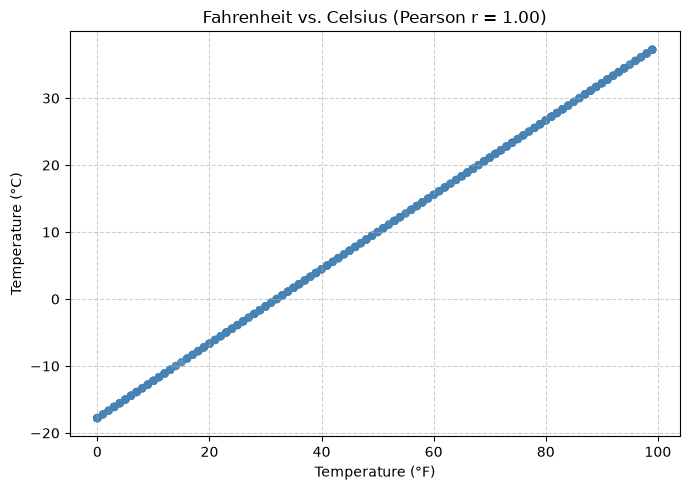

In [5]:
import matplotlib.pyplot as plt
from scipy import stats
# --- Pearson Correlation Implementation ---
print("\n--- Pearson Correlation ---")

# Method 1: Pandas built-in correlation matrix
corr_matrix = df_interval.corr(method='pearson')
print("Correlation Matrix:")
print(corr_matrix)

# Method 2: SciPy for scalar r and p-value
r_val, p_val = stats.pearsonr(
    df_interval['Temperature (Fahrenheit)'],
    df_interval['Temperature (Celsius)']
)
print(f"\nPearson r: {r_val:.4f}")
print(f"p-value  : {p_val:.4e}")
print("Interpretation: Pearson r is invariant under positive linear/affine transformations.")

# Visualization
plt.figure(figsize=(7, 5))
plt.scatter(
    df_interval['Temperature (Fahrenheit)'],
    df_interval['Temperature (Celsius)'],
    alpha=0.4,
    color='steelblue',
    edgecolors='none'
)
plt.title(f"Fahrenheit vs. Celsius (Pearson r = {r_val:.2f})")
plt.xlabel("Temperature (°F)")
plt.ylabel("Temperature (°C)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

---

### Concept 06: Ratio Data & Absolute Zero
**Question:**
> What gives Ratio data the highest mathematical expressiveness among measurement scales? How does an absolute zero unlock multiplicative ratios?

**Answer:**
- **Theoretical Intuition:** Ratio data possesses equal intervals *and* a unique, non-arbitrary, natural absolute zero point ($0.0$) signifying the total absence of the measured entity.
- **Technical Mechanics:** The scale is invariant under similarity transformations ($y = ax, a > 0$). Because origin zero is fixed, the ratio between any two points $\frac{x_2}{x_1} = \frac{a x_2}{a x_1}$ remains constant regardless of the unit scale chosen (e.g., USD vs INR, meters vs feet, Kelvin vs Rankine).
- **Permissible Operations:** All arithmetic operations ($+, -, \times, \div$). All moments of distribution, geometric mean, harmonic mean, percentage differences, and coefficient of variation.
- **Key Examples from Source:** Annual Income in dollars ($\$0.00$ = no income; $\$200$ is strictly twice $\$100$), Weight in kilograms ($0\text{ kg}$ = no mass), Temperature in Kelvin ($0\text{ K}$ = cessation of thermodynamic energy).
- **Key Terminology:** Absolute zero, Scale invariance, Ratio scale.



In [6]:
# Ratio Data Pipeline: Income Distribution and Scale Invariance Verification
np.random.seed(0)
# ratio_data = np.random.rand(num_samples) * 1000
ratio_data = np.random.randint(2000, 10000, size=num_samples)  # Annual Income in dollars
df_ratio = pd.DataFrame(ratio_data, columns=['Income'])

# Verify scale invariance under currency scaling (e.g., USD to Cents)
val1_usd = df_ratio['Income'].iloc[0]
val2_usd = df_ratio['Income'].iloc[1]

ratio_usd = val2_usd / val1_usd
ratio_cents = (val2_usd * 100) / (val1_usd * 100)

print("--- Ratio Scale Invariance Proof ---")
print(f"USD Values: ${val1_usd:.2f}, ${val2_usd:.2f} -> Ratio: {ratio_usd:.2f}")
print(f"Cents Values: {val1_usd*100:.2f}¢, {val2_usd*100:.2f}¢ -> Ratio: {ratio_cents:.2f}")
print(f"Multiplicative Ratio Invariant? {np.isclose(ratio_usd, ratio_cents)}")

print("\n--- Ratio Descriptive Statistics ---")
print(df_ratio.describe())



--- Ratio Scale Invariance Proof ---
USD Values: $4732.00, $4607.00 -> Ratio: 0.97
Cents Values: 473200.00¢, 460700.00¢ -> Ratio: 0.97
Multiplicative Ratio Invariant? True

--- Ratio Descriptive Statistics ---
            Income
count  1000.000000
mean   5975.858000
std    2311.729735
min    2000.000000
25%    3984.000000
50%    5951.500000
75%    7976.000000
max    9997.000000


---

### Concept 07 & 08: Discrete vs. Continuous Quantitative Data
**Question:**
> Rigorously contrast Discrete and Continuous random variables from measure-theoretic and computational perspectives. How does this dictate probability function modeling?

**Answer:**
- **Theoretical Intuition:**
  - **Discrete Data:** Can only assume isolated, distinct values from a countable set (finite or countably infinite, e.g., $\{0, 1, 2, \dots\}$). Values represent distinct counts that cannot be meaningfully partitioned into fractional components.
  - **Continuous Data:** Can assume any real value within an interval $(a, b) \subseteq \mathbb{R}$. Values represent physical measurements produced by an analog process with arbitrary theoretical precision.
- **Probability Modeling:**
  - Discrete variables are modeled by a **Probability Mass Function (PMF)**: $P(X = k) \ge 0$, where $\sum_k P(X = k) = 1$.
  - Continuous variables are modeled by a **Probability Density Function (PDF)**: For any exact single point $c$, $P(X = c) = \int_c^c f(x)dx = 0$. Probabilities exist strictly over intervals: $P(a \le X \le b) = \int_a^b f(x) dx$.
- **Source Examples:** Number of Children (Discrete); Weight in kg (Continuous).
- **Key Terminology:** Countable support, Uncountable continuum, PMF vs PDF, Infinitesimal granularity.



In [7]:
# Discrete vs Continuous Data Modeling

np.random.seed(0)
num_samples = 1000

# Discrete: Number of children (integers [1, 9])
discrete_data = np.random.randint(1, 10, size=num_samples)
df_discrete = pd.DataFrame(discrete_data, columns=['Number of Children'])

# Continuous: Weight in kg (continuous uniform [0, 10))
continuous_data = np.random.rand(num_samples) * 10
df_continuous = pd.DataFrame(continuous_data, columns=['Weight'])

print("--- Discrete Sample Head ---")
print(df_discrete.head(3))
print("Discrete Dtype:", df_discrete['Number of Children'].dtype)

print("\n--- Continuous Sample Head ---")
print(df_continuous.head(3))
print("Continuous Dtype:", df_continuous['Weight'].dtype)



--- Discrete Sample Head ---
   Number of Children
0                   6
1                   1
2                   4
Discrete Dtype: int32

--- Continuous Sample Head ---
     Weight
0  1.566535
1  6.841257
2  0.340708
Continuous Dtype: float64


---

### Concept 09 & 10: Central Tendency Diagnostics: Mode & Mean Degradation
**Question:**
> Why is `scipy.stats.mode` / sample mode statistically informative for discrete variables but mathematically and practically degenerate for continuous floating-point variables?

**Answer:**
- **Theoretical Intuition:**
  - For discrete distributions with finite support, individual outcomes have non-zero probability mass ($P(X = x) > 0$). Identical values reoccur frequently; thus, the empirical mode $\arg\max_x \text{freq}(x)$ reliably identifies the distribution's highest peak.
  - For continuous distributions, $P(X = x) = 0$ for any exact real value. In empirical floating-point arrays sampled from continuous distributions (e.g., IEEE 754 float64), precision extends up to 53 bits of mantissa (~15-17 decimal digits). The probability of observing two identical floats is nearly zero ($P(x_i = x_j) \approx 0$ for $i \neq j$).
- **The Degeneracy:** Calculating the sample mode on unbinned continuous floats yields either the first element encountered or an arbitrary float with frequency 1, rendering it statistically useless.
- **Production Solution:**
  1. Bin the continuous data into a histogram / discrete intervals and extract the modal bin.
  2. Estimate continuous mode via **Kernel Density Estimation (KDE)**: $\hat{x}_{\text{mode}} = \arg\max_x \hat{f}_{\text{KDE}}(x)$.



ModeResult(mode=array([4], dtype=int32), count=array([132]))
--- Discrete Data Metrics ---
Mode of Number of Children: 4 (Frequency: 132)
Mean of Number of Children: 4.9240

--- Continuous Data Metrics (Unbinned) ---
Mode of Weight: 0.000606 (Frequency: 1) -> DEGENERATE / MEANINGLESS
Mean of Weight: 5.0090 -> STABLE AND MEANINGFUL
Estimated Continuous Mode via KDE Peak: 7.1263 kg


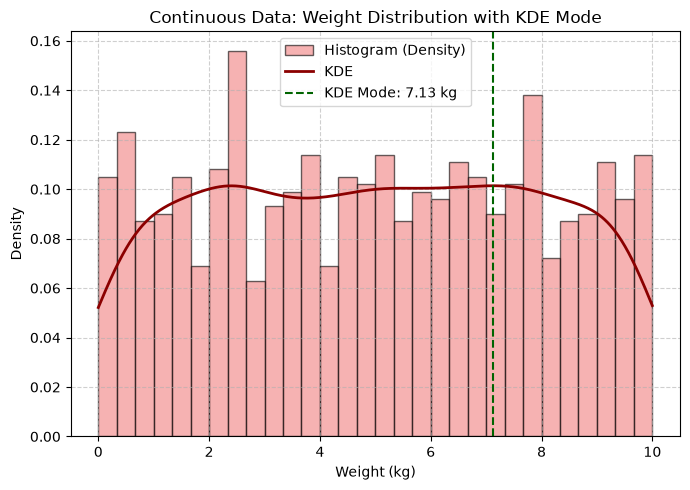

In [8]:
# Deep Dive: Scipy Mode Behavior on Discrete vs Continuous
# Discrete Mode calculation
mode_discrete = stats.mode(df_discrete['Number of Children'], keepdims=True)
mean_discrete = np.mean(df_discrete['Number of Children'])
print(mode_discrete)
print("--- Discrete Data Metrics ---")
print(f"Mode of Number of Children: {mode_discrete.mode[0]} (Frequency: {mode_discrete.count[0]})")
print(f"Mean of Number of Children: {mean_discrete:.4f}")

# Continuous Mode calculation (Degenerate)
mode_continuous = stats.mode(df_continuous['Weight'], keepdims=True)
mean_continuous = np.mean(df_continuous['Weight'])

print("\n--- Continuous Data Metrics (Unbinned) ---")
print(f"Mode of Weight: {mode_continuous.mode[0]:.6f} (Frequency: {mode_continuous.count[0]}) -> DEGENERATE / MEANINGLESS")
print(f"Mean of Weight: {mean_continuous:.4f} -> STABLE AND MEANINGFUL")

# Proper Production Approach for Continuous Mode: Kernel Density Estimation (KDE)
kde = stats.gaussian_kde(df_continuous['Weight']) # Fit KDE to continuous data
x_eval = np.linspace(df_continuous['Weight'].min(), df_continuous['Weight'].max(), 1000) # Evaluation points
kde_pdf = kde(x_eval) # Evaluate KDE at evaluation points
continuous_kde_mode = x_eval[np.argmax(kde_pdf)] # Find the peak of the KDE

print(f"Estimated Continuous Mode via KDE Peak: {continuous_kde_mode:.4f} kg")
# frequency distribution plot for continuous data
plt.figure(figsize=(7, 5))
plt.hist(df_continuous['Weight'], bins=30, density=True, alpha=0.6, color='lightcoral', edgecolor='black', label='Histogram (Density)')
plt.plot(x_eval, kde_pdf, color='darkred', lw=2, label='KDE')
plt.axvline(continuous_kde_mode, color='darkgreen', linestyle='--', label=f'KDE Mode: {continuous_kde_mode:.2f} kg')
plt.title("Continuous Data: Weight Distribution with KDE Mode")
plt.xlabel("Weight (kg)")
plt.ylabel("Density")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()



---

### Concept 11: Data Collection: Surveys & Self-Reporting Biases
**Question:**
> What are the primary structural trade-offs of Surveys as a data collection modality, and what statistical biases must an engineer account for during data cleansing?

**Answer:**
- **Theoretical Intuition:** Surveys gather structured responses to standardized queries across a sample from a target population.
- **Advantages:** Highly scalable, cost-effective, easily parallelized, and capable of gathering self-reported sentiments, opinions, and demographic classifications across large cohorts.
- **Critical Limitations & Biases:**
  1. **Non-Response Bias:** Individuals who refuse or fail to respond systematically differ from respondents (e.g., disaffected customers don't fill out satisfaction surveys).
  2. **Social Desirability / Self-Reporting Bias:** Participants underreport undesirable behaviors (e.g., debt, addiction) and overreport virtues (e.g., income, exercise).
  3. **Acquiescence Bias:** Tendency of respondents to agree with statements by default.
  4. **Inability to Prove Causality:** Only cross-sectional associations can be identified, not causal effects.
- **Source Examples:** Election polls (exit polling), Customer satisfaction surveys (scale 1 to 5).



In [9]:
# Simulating Non-Response Bias in Customer Satisfaction Surveys
np.random.seed(42)
total_population = 10000

# True population satisfaction: 1 to 5
true_satisfaction = np.random.choice([1, 2, 3, 4, 5], size=total_population, p=[0.15, 0.20, 0.35, 0.20, 0.10])

# Response probabilities: Extremely dissatisfied (1) and extremely satisfied (5) respond more often
response_prob = np.where(true_satisfaction == 1, 0.8, # where(condition, value_if_true, value_if_false)
                np.where(true_satisfaction == 5, 0.7, 0.2))

responded = np.random.rand(total_population) < response_prob
survey_sample = true_satisfaction[responded]

print(f"True Population Mean Satisfaction:   {np.mean(true_satisfaction):.3f}")
print(f"Survey Observed Mean Satisfaction:  {np.mean(survey_sample):.3f}")
print(f"Observed Sample Size: {len(survey_sample)} out of {total_population}")
print("-> Bimodal response bias distorts the population reality!")




True Population Mean Satisfaction:   2.876
Survey Observed Mean Satisfaction:  2.678
Observed Sample Size: 3361 out of 10000
-> Bimodal response bias distorts the population reality!


---

### Concept 12: Data Collection: Controlled Experiments & Causal Inference
**Question:**
> How do controlled experiments establish causality, and what is the role of the independent variable, dependent variable, and random assignment?

**Answer:**
- **Theoretical Intuition:** Controlled experiments isolate causal mechanisms ($X \to Y$) by manipulating one or more explanatory factors (**Independent Variables**) while holding all extraneous variables constant and measuring shifts in the response outcome (**Dependent Variable**).
- **Core Mechanics:**
  - **Treatment vs. Control Groups:** The treatment group receives the intervention; the control group receives a baseline/placebo.
  - **Random Assignment:** Guarantees that confounding variables (both observed and unobserved) are distributed symmetrically across groups, preventing omitted-variable bias.
- **Source Examples:**
  - *Plant Growth Study:* Fertilizer brand (Independent) $\to$ Growth in cm (Dependent).
  - *Sleep Study:* Screen time before bed vs. no screens (Independent) $\to$ Sleep Quality Index (Dependent).
- **Disadvantages:** High financial and operational cost, ethical restrictions (cannot randomly expose subjects to toxic chemicals), and artificial lab conditions limiting ecological validity.



In [10]:
# Controlled Experiment Simulation: Two-Sample A/B Hypothesis Testing
np.random.seed(42)
n_per_group = 150

# Simulating Sleep Quality Scores (1-100)
# Group A (Control - No Screens): Normal(mu=75, sigma=10)
control_group = np.random.normal(loc=75, scale=10, size=n_per_group)

# Group B (Treatment - Screen Time): Normal(mu=68, sigma=12)
treatment_group = np.random.normal(loc=68, scale=12, size=n_per_group)

# Independent two-sample t-test to evaluate causal treatment effect
t_stat, p_val = stats.ttest_ind(control_group, treatment_group)

print("--- Controlled Experiment: Causal Sleep Study ---")
print(f"Control (No Screen) Mean Sleep Score:    {np.mean(control_group):.2f}")
print(f"Treatment (Screen) Mean Sleep Score:     {np.mean(treatment_group):.2f}")
print(f"Difference in Means (Treatment Effect):   {np.mean(treatment_group) - np.mean(control_group):.2f}")
print(f"Two-Sample Welch's t-statistic:           {t_stat:.4f}")
print(f"P-value:                                  {p_val:.4e}")
print(f"Statistically Significant (alpha=0.01)?   {p_val < 0.01}")



--- Controlled Experiment: Causal Sleep Study ---
Control (No Screen) Mean Sleep Score:    74.18
Treatment (Screen) Mean Sleep Score:     68.85
Difference in Means (Treatment Effect):   -5.32
Two-Sample Welch's t-statistic:           4.2151
P-value:                                  3.3137e-05
Statistically Significant (alpha=0.01)?   True


---

### Concept 13: Data Collection: Observational Studies vs. Confounding
**Question:**
> What is an Observational Study, and why does the absence of active intervention make it susceptible to confounding and Berkson's / Simpson's paradoxes?

**Answer:**
- **Theoretical Intuition:** Observational studies observe and record events, behaviors, and covariates as they naturally occur in the real world without active intervention or random assignment.
- **Key Characteristics:**
  - Ideal when experimental manipulation is unethical (e.g., studying the impact of smoking or toxic waste exposure) or physically infeasible (e.g., galactic cosmology, macroeconomic policy).
  - Can establish **correlation** and **predictive association**, but *never direct causality* without stringent quasi-experimental econometric controls (e.g., instrumental variables, regression discontinuity, propensity score matching).
- **Confounding Variables:** A third variable $Z$ correlated with both exposure $X$ and outcome $Y$ can introduce spurious correlations or mask real relationships.
- **Source Examples:**
  - *Wildlife Observation:* Ecologists observing bird foraging patterns in a public park.
  - *Traffic Patterns:* City planners capturing camera telemetry at peak hours to optimize traffic signal timings.



In [11]:
# Observational Confounding (Simpson's Paradox Illustration)
# Confounder Z: Weather Condition (0 = Sunny, 1 = Rainy)
np.random.seed(42)
n = 1000
weather = np.random.binomial(1, 0.4, size=n)

# Exposure X: Coffee Consumption (higher on rainy days)
coffee = np.random.poisson(lam=2 + 2 * weather)

# Outcome Y: Productivity (rain reduces baseline energy, but coffee boosts it)
productivity = 50 - 15 * weather + 5 * coffee + np.random.normal(0, 3, size=n)

obs_df = pd.DataFrame({'Weather': weather, 'Coffee': coffee, 'Productivity': productivity})

# Naive Observational Correlation (Ignoring Weather confounder)
naive_corr = obs_df['Coffee'].corr(obs_df['Productivity'])
print(f"Naive Observational Correlation (Coffee vs Productivity): {naive_corr:.3f}")

# Stratified / Controlled Correlation (Observing within weather condition)
print(f"Controlled Correlation (Sunny Days Only): {obs_df[obs_df['Weather']==0]['Coffee'].corr(obs_df[obs_df['Weather']==0]['Productivity']):.3f}")
print(f"Controlled Correlation (Rainy Days Only): {obs_df[obs_df['Weather']==1]['Coffee'].corr(obs_df[obs_df['Weather']==1]['Productivity']):.3f}")
print("-> Omitted confounders in observational data invert or distort true effects!")



Naive Observational Correlation (Coffee vs Productivity): 0.634
Controlled Correlation (Sunny Days Only): 0.922
Controlled Correlation (Rainy Days Only): 0.955
-> Omitted confounders in observational data invert or distort true effects!


---

### Concept 14 & 15: Sampling Theory: SRS Failure & Stratified Correction
**Question:**
> Define the statistical objective of Sampling. Why does Simple Random Sampling (SRS) often fail in real-world scenarios with subpopulation imbalance, and how does Stratified Sampling solve this?

**Answer:**
- **Theoretical Intuition:** Sampling is the process of selecting an unbiased representative subset $S \subset \mathcal{P}$ from a population $\mathcal{P}$ to estimate unknown population parameters (mean $\mu$, variance $\sigma^2$, proportion $p$) using sample statistics ($\bar{x}, s^2, \hat{p}$).
- **The Failure Mode of Simple Random Sampling (SRS):**
  - In SRS, every individual in the population has an equal probability of selection: $P(i) = \frac{1}{N}$.
  - If the target population contains small, critical minority strata (e.g., regional high schools, specialized demographics, rare manufacturing defects), SRS suffers from high sampling variance in those sub-strata. A random draw can easily underrepresent or completely omit low-frequency groups, introducing severe sample allocation bias.
- **The Stratified Sampling Solution:**
  - Partition the population into $K$ mutually exclusive and collectively exhaustive homogeneous strata: $\mathcal{P} = S_1 \cup S_2 \dots \cup S_K$.
  - Perform independent random sampling within each stratum proportional to its population weight $W_k = N_k / N$.
  - Guaranteed representation of all subgroups, significantly lowering the variance of the overall population estimator: $\text{Var}(\bar{x}_{\text{strat}}) \le \text{Var}(\bar{x}_{\text{SRS}})$.



In [12]:
# Demonstrating Simple Random Sampling vs Stratified Sampling on Imbalanced Population
np.random.seed(42)

# Simulated population of 10,000 students across 3 school regions:
# Region A (Urban, 70%), Region B (Suburban, 25%), Region C (Rural, 5%)
pop_size = 10000
strata_sizes = {'Urban': 7000, 'Suburban': 2500, 'Rural': 500}

population_records = []
for region, count in strata_sizes.items():
    # Rural students have distinct subject preferences
    score_mean = 85 if region == 'Rural' else (72 if region == 'Suburban' else 65)
    scores = np.random.normal(loc=score_mean, scale=5, size=count)
    for s in scores:
        population_records.append({'Region': region, 'MathScore': s})

pop_df = pd.DataFrame(population_records)
true_pop_mean = pop_df['MathScore'].mean()

# Method 1: Simple Random Sample (n = 100)
srs_sample = pop_df.sample(n=100, random_state=1)
srs_counts = srs_sample['Region'].value_counts()

# Method 2: Stratified Sample (Proportional allocation, n = 100)
strat_sample = pop_df.groupby('Region', group_keys=False).sample(frac=100/pop_size, random_state=1)

strat_counts = strat_sample['Region'].value_counts()

print(f"True Population Overall Mean: {true_pop_mean:.3f}")
print(f"SRS Estimated Mean:          {srs_sample['MathScore'].mean():.3f} (Sampled Rural count: {srs_counts.get('Rural', 0)})")
print(f"Stratified Estimated Mean:   {strat_sample['MathScore'].mean():.3f} (Sampled Rural count: {strat_counts.get('Rural', 0)})")
print("\nSubgroup Breakdown in Sample of 100:")
print(f"True Expected Rural Count:  {strata_sizes['Rural'] / pop_size * 100:.0f}")
print(f"Actual SRS Rural Count:     {srs_counts.get('Rural', 0)} (High variance risk!)")
print(f"Stratified Rural Count:     {strat_counts.get('Rural', 0)} (Exact target proportion)")



True Population Overall Mean: 67.739
SRS Estimated Mean:          67.487 (Sampled Rural count: 5)
Stratified Estimated Mean:   67.472 (Sampled Rural count: 5)

Subgroup Breakdown in Sample of 100:
True Expected Rural Count:  5
Actual SRS Rural Count:     5 (High variance risk!)
Stratified Rural Count:     5 (Exact target proportion)


---

### Concept 16: Comprehensive Real-World Feature Store Pipeline
**Question:**
> Construct an end-to-end Python script modeling the complete 7-variable survey dataset from the session notes:
> `[Color, Satisfaction, Temperature_F, Income, Number_of_Children, Weight, Temperature_K]`.
> Validate the data types and implement appropriate statistical checks for each column.



In [13]:
# Production End-to-End Dataset Construction matching Session Specifications
np.random.seed(0)
num_samples = 1000

# 1. Color: Favorite color (Nominal)
colors = ['LightSlateGray', 'MediumSlateBlue', 'Indigo', 'BurlyWood', 'SeaGreen']
color_data = np.random.choice(colors, size=num_samples)

# 2. Satisfaction: Satisfaction level (Ordinal)
satisfaction_levels = ['Low', 'Medium', 'High']
satisfaction_data = np.random.choice(satisfaction_levels, size=num_samples, p=[0.25, 0.50, 0.25])

# 3. Temperature: Fahrenheit (Interval)
temp_f = np.random.randint(20, 100, size=num_samples)

# 4. Income: Annual income in dollars (Ratio)
income = np.round(np.random.uniform(100.0, 1000.0, size=num_samples), 2)

# 5. Number of Children: Count (Discrete Quantitative)
children = np.random.randint(0, 10, size=num_samples)

# 6. Weight: Weight in kg (Continuous Quantitative)
weight = np.round(np.random.uniform(1.0, 10.0, size=num_samples), 2)

# 7. Temperature Kelvin: Absolute Zero baseline (Ratio)
temp_k = np.round((temp_f - 32) * 5/9 + 273.15, 2)

# Construct Consolidated Master DataFrame
master_df = pd.DataFrame({
    'Color': color_data,
    'Satisfaction': pd.Categorical(satisfaction_data, categories=['Low', 'Medium', 'High'], ordered=True),
    'Temperature_F': temp_f,
    'Income': income,
    'Number_of_Children': children,
    'Weight': weight,
    'Temperature_K': temp_k
})

print("--- Master Dataset Head (Matching Excerpt Schema) ---")
print(master_df.head())
print("\n--- Schema & Storage Profiling ---")
master_df.info()



--- Master Dataset Head (Matching Excerpt Schema) ---
            Color Satisfaction  Temperature_F  Income  Number_of_Children  \
0        SeaGreen       Medium             72  243.11                   9   
1  LightSlateGray          Low             63  989.57                   5   
2       BurlyWood       Medium             70  457.96                   2   
3       BurlyWood          Low             36  450.50                   9   
4       BurlyWood       Medium             84  498.57                   8   

   Weight  Temperature_K  
0    1.34         295.37  
1    8.98         290.37  
2    7.01         294.26  
3    4.80         275.37  
4    3.39         302.04  

--- Schema & Storage Profiling ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   Color               1000 non-null   str     
 1   Satisfaction        1000 non-null   

## 4. Practical Hands-On Coding Exercises

### Exercise 1: Identify and Cast Measurement Scales
Given the raw un-typed DataFrame below, convert each column to its optimal, mathematically correct pandas dtype (e.g., `'category'`, `pd.CategoricalDtype(..., ordered=True)`, `'int64'`, `'float64'`).



In [14]:
# Exercise 1: Skeleton for Scale Type Casting
raw_test_data = pd.DataFrame({
    'CustomerID': [101, 102, 103, 104, 105],
    'FeedbackRating': ['Good', 'Poor', 'Excellent', 'Fair', 'Good'],
    'City': ['Dallas', 'Seattle', 'Chicago', 'Dallas', 'Austin'],
    'VisitsPerMonth': ['2', '5', '1', '12', '4'],
    'BillAmount': ['120.50', '45.10', '89.00', '310.25', '67.80']
})

raw_test_data.info()

### YOUR IMPLEMENTATION HERE:
# 1. Cast CustomerID to string or object (Nominal identifier)
# 2. Cast FeedbackRating to ordered Categorical ['Poor', 'Fair', 'Good', 'Excellent']
# 3. Cast City to unordered category
# 4. Cast VisitsPerMonth to discrete int32
# 5. Cast BillAmount to continuous float64

# --- Solution ---
clean_df = raw_test_data.copy()
clean_df['CustomerID'] = clean_df['CustomerID'].astype(str)
rating_order = pd.CategoricalDtype(categories=['Poor', 'Fair', 'Good', 'Excellent'], ordered=True)
clean_df['FeedbackRating'] = clean_df['FeedbackRating'].astype(rating_order)
clean_df['City'] = clean_df['City'].astype('category')
clean_df['VisitsPerMonth'] = clean_df['VisitsPerMonth'].astype(int)
clean_df['BillAmount'] = clean_df['BillAmount'].astype(float)

print("Exercise 1 Output:")
clean_df.info()



<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   CustomerID      5 non-null      int64
 1   FeedbackRating  5 non-null      str  
 2   City            5 non-null      str  
 3   VisitsPerMonth  5 non-null      str  
 4   BillAmount      5 non-null      str  
dtypes: int64(1), str(4)
memory usage: 422.0 bytes
Exercise 1 Output:
<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   CustomerID      5 non-null      str     
 1   FeedbackRating  5 non-null      category
 2   City            5 non-null      category
 3   VisitsPerMonth  5 non-null      int64   
 4   BillAmount      5 non-null      float64 
dtypes: category(2), float64(1), int64(1), str(1)
memory usage: 561.0 bytes


### Exercise 2: Implementing Stratified Train-Test Split from First Principles
Without using `scikit-learn`'s `train_test_split(..., stratify=...)`, implement a stratified sampling function that partitions a DataFrame into 80% train and 20% test splits while strictly preserving class proportions.



In [15]:
# Exercise 2: Stratified Sampling Split from Scratch
def custom_stratified_split(df: pd.DataFrame, target_col: str, test_size: float = 0.2, random_state: int = 42):
    test_indices = []
    
    for class_val, group in df.groupby(target_col):
        n_test = int(np.round(len(group) * test_size))
        sampled = group.sample(n=n_test, random_state=random_state)
        test_indices.extend(sampled.index.tolist())
        
    test_df = df.loc[test_indices].copy()
    train_df = df.drop(index=test_indices).copy()
    return train_df, test_df

# Testing the custom stratified splitter
train_set, test_set = custom_stratified_split(master_df, target_col='Satisfaction', test_size=0.2)

print("Exercise 2 Verification:")
print("Original Proportions:\n", master_df['Satisfaction'].value_counts(normalize=True))
print("\nTrain Proportions:\n", train_set['Satisfaction'].value_counts(normalize=True))
print("\nTest Proportions:\n", test_set['Satisfaction'].value_counts(normalize=True))



Exercise 2 Verification:
Original Proportions:
 Satisfaction
Medium    0.473
High      0.284
Low       0.243
Name: proportion, dtype: float64

Train Proportions:
 Satisfaction
Medium    0.473091
High      0.284105
Low       0.242804
Name: proportion, dtype: float64

Test Proportions:
 Satisfaction
Medium    0.472637
High      0.283582
Low       0.243781
Name: proportion, dtype: float64


## 5. Comprehensive Quick Reference Guide

| Data Scale | Ordering? | Equal Intervals? | True Zero? | Permissible Central Tendency | Permissible Operations | Example Features |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Nominal** | No | No | No | **Mode** | $=, \neq$, Frequency counts | Color, Gender, Zip Code |
| **Ordinal** | **Yes** | No | No | **Median**, Mode | $=, \neq, <, >$, Percentiles | Satisfaction, Education Level |
| **Interval**| **Yes** | **Yes** | No | **Mean**, Median, Mode | $+ , -$, Std Dev, Pearson $r$ | Temp ($^\circ\text{F}, ^\circ\text{C}$), IQ, Calendar Year |
| **Ratio** | **Yes** | **Yes** | **Yes** | **All** (Mean, Geometric Mean, etc.) | $+ , -, \times, \div$, Ratios, CV | Income, Mass, Distance, Kelvin |

### Data Collection Modality Cheat Sheet:
- **Surveys:**
  - *Goal:* Broad population sentiment and behavioral frequency.
  - *Risk:* Non-response bias, acquiescence bias, social desirability.
  - *Causality:* **No** (purely associational).
- **Controlled Experiments:**
  - *Goal:* Causal attribution ($X \implies Y$).
  - *Mechanism:* Random assignment + active manipulation of independent variables.
  - *Risk:* High expense, ethical ceilings, low external validity.
  - *Causality:* **Yes**.
- **Observational Studies:**
  - *Goal:* In-situ natural behavior monitoring.
  - *Risk:* Confounders, reverse causality, selection bias.
  - *Causality:* **No** (unless isolated via advanced causal econometric techniques).



## 6. Interview Architecture Summary

When addressing Data Types and Data Collection in technical interviews:

1. **Defend Mathematical Legitimacy First:**
   Always inspect whether an operation is statistically legitimate before writing pipeline code. Do not compute means on ordinal scales or ratios on interval temperatures.
2. **Be Ready for the Continuous Mode Trap:**
   State clearly that `stats.mode()` or sample mode on raw continuous floats degenerates due to IEEE 754 precision; propose histogram modal bins or Kernel Density Estimation (KDE) as the production remedy.
3. **Guard Against Encoding Traps:**
   Never map nominal features to integers without using One-Hot Encoding or target encoding in parametric models; otherwise, false Euclidean distances will distort gradient updates.
4. **Distinguish Association from Causation:**
   Always remember: observational studies and surveys measure association ($P(Y|X)$); controlled experiments establish interventional causality ($P(Y|\text{do}(X))$).

